# Evaluación de estrategias de cobertura frente a las fluctuaciones del precio del cobre cátodo en la mediana minería chilena

**Memoria de título — Ingeniería Comercial, Universidad Técnica Federico Santa María**
Autor: Vicente Yáñez Reinoso · Profesor guía: Joaquín Vergara

Este cuaderno contiene el análisis cuantitativo de la memoria. Cada sección corresponde a un apartado del capítulo 4 y reproduce sus tablas y figuras con la numeración de la tesis. El procedimiento se describe en el capítulo 3.

**Datos.** Precio contado y precio a tres meses del cobre Grado A en la Bolsa de Metales de Londres, informados por Cochilco, de enero de 2005 a julio de 2026 (promedios mensuales; 259 observaciones y 258 rendimientos), y serie mensual del precio contado desde 1990 para el análisis de sensibilidad. Los archivos se leen directamente desde el repositorio `vicenteyanezreinoso01-spec/tesis_mineria` (carpeta `datos`).

**Cómo ejecutarlo.** En Colab: *Entorno de ejecución → Ejecutar todas*. Cada celda de código es independiente: carga sus datos y, cuando corresponde, regenera los mismos 10.000 escenarios con la semilla 2026, por lo que puede ejecutarse por separado. Las celdas de los apartados 4.3 y 4.6 tardan entre 1 y 3 minutos cada una.

**Versiones utilizadas** (apartado 3.6.3): Python 3.13, pandas 2.2.3, NumPy 2.4.6, SciPy 1.16.3, statsmodels 0.15.0 y arch 9.0.0. La celda final imprime las versiones del entorno en que se ejecuta.

| Sección del cuaderno | Apartado de la tesis | Tablas y figuras |
|---|---|---|
| 1 | 4.2.1 y 4.2.2 | Tabla 1; Figuras 1, 2 y 3; Tablas 8 y 9 |
| 2 | 4.2.3 | Figuras 4, 5 y 6; Tabla 10 |
| 3 | 4.3.1 y 4.3.2 | Figuras 7 a 10; Tablas 11 a 16 |
| 4 | 4.4 | Figura 11; Tabla 17 |
| 5 | 4.5 | Tablas 18 a 21; Figuras 12 y 13 |
| 6 | 4.6 | Tablas 22 a 24; Figura 14 |
| 7 | 3.5, 3.6, 4.5 y 4.6 | Verificaciones complementarias citadas en el texto |


## 1. Serie de precios y propiedades estadísticas (apartados 4.2.1 y 4.2.2)

- **A1:** parámetros de la empresa de referencia (Tabla 1, apartado 1.4).
- **A1b:** precio contado y a tres meses (Figura 1) y rendimientos mensuales (Figura 2).
- **A2:** estadística descriptiva de los rendimientos, ecuación (1) (Tabla 8).
- **A3:** pruebas de Jarque-Bera, ADF, Ljung-Box y ARCH-LM (Tabla 9).
- **A4:** distribución de los rendimientos frente a la normal (Figura 3).

=== A1. EMPRESA DE REFERENCIA (Tabla 1) ===
Producción anual (t)                         11,307.5500
Producción mensual (t)                          942.2958
Libras por mes                            2,077,406.4074
P0 julio 2026 (US$/lb)                            6.1349
F0 julio 2026 (US$/lb)                            6.1434
Ingreso de referencia 12 meses (MM US$)         152.9367
Umbral 80% (MM US$)                             122.3493


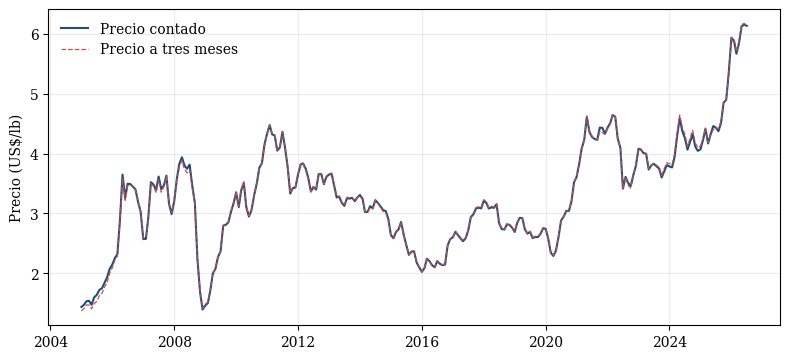

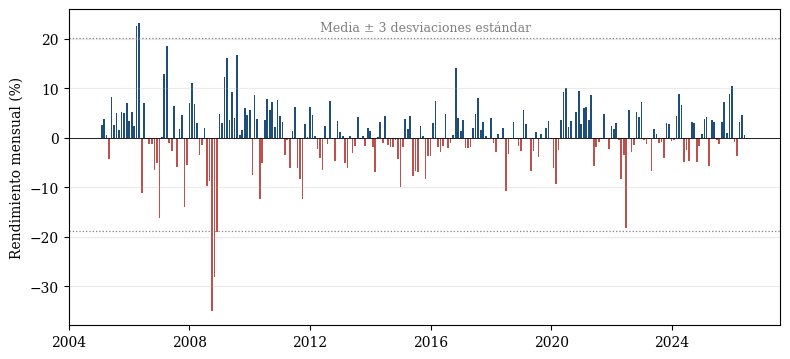


=== A2. ESTADÍSTICA DESCRIPTIVA (Tabla 8) ===
Observaciones                             258
Media mensual (%)                      0.5623
Desv. estándar mensual (%)             6.4876
Volatilidad anual (%)                 22.4739
Asimetría                             -0.8031
Exceso de curtosis                     5.3629
Rendimiento mínimo (%)               -35.0137
Mes del mínimo                        2008-10
Rendimiento máximo (%)                23.0770
Mes del máximo                        2006-05
Desv. estándar variación 12 meses      0.2844
Percentil 5 variación 12 meses (%)   -26.7021
Peor variación 12 meses (%)          -57.9761
Fin de la peor ventana                2009-02
Meses con caída > 10% (%)              3.8760

=== A3. PRUEBAS ESTADÍSTICAS (Tabla 9) ===
                                            Hipótesis nula  Estadístico  Valor p ¿Se rechaza al 5%?
Jarque-Bera                                     Normalidad     336.9116   0.0000                 Sí
ADF logaritmo del p

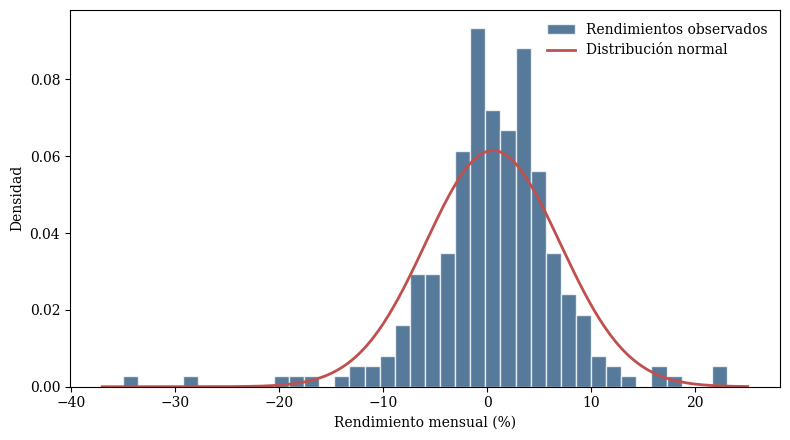

In [8]:
# ==== APARTADOS 4.2.1 Y 4.2.2: SERIE DE PRECIOS Y PROPIEDADES ESTADÍSTICAS ====
# Celda independiente: carga los datos desde GitHub. Produce la Tabla 1, las Figuras 1 a 3
# y las Tablas 8 y 9.
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

ARCHIVO_MENSUAL = "https://raw.githubusercontent.com/vicenteyanezreinoso01-spec/tesis_mineria/main/datos/Precio_cobre_mensual_1960_2026.xlsx"

# --- Datos: promedios mensuales del precio contado y a tres meses (apartado 3.3.1) ---
cf = pd.read_excel(ARCHIVO_MENSUAL, sheet_name="Contado y futuro 2005-2026")
cf.columns = ["mes", "P_cent", "F_cent", "dias"]
cf.index = pd.PeriodIndex(cf["mes"], freq="M")
cf = cf.loc[:"2026-07"]
m = pd.DataFrame({"P": cf["P_cent"] / 100, "F": cf["F_cent"] / 100})   # US$/lb
lp = np.log(m["P"])
r = lp.diff().dropna()            # ecuación (1)
w12 = lp.diff(12).dropna()        # variación logarítmica en 12 meses

# --- A1. Empresa de referencia (capítulo 1, Tabla 1) ---
Q_ANUAL = 226151 / 20             # t de cobre fino por año
QM = Q_ANUAL / 12                 # t por mes
K_LB = 2204.6223                  # lb por t
P0, F0 = m["P"].iloc[-1], m["F"].iloc[-1]
I_REF = 12 * QM * K_LB * P0       # ingreso de 12 meses si el precio se mantuviera en P0
empresa = pd.Series({
    "Producción anual (t)": Q_ANUAL, "Producción mensual (t)": QM,
    "Libras por mes": QM * K_LB, "P0 julio 2026 (US$/lb)": P0, "F0 julio 2026 (US$/lb)": F0,
    "Ingreso de referencia 12 meses (MM US$)": I_REF / 1e6,
    "Umbral 80% (MM US$)": 0.8 * I_REF / 1e6})
print("=== A1. EMPRESA DE REFERENCIA (Tabla 1) ===");  print(empresa.to_string())

# --- A1b. Figuras 1 y 2 (apartado 4.2.1; sin título, el título va en la tesis) ---
plt.rcParams.update({"font.family": "serif", "font.size": 10})
AZ, RO = "#1f4e79", "#c0504d"
t = m.index.to_timestamp()
fig, ax = plt.subplots(figsize=(8, 3.7))                       # Figura 1
ax.plot(t, m["P"], color=AZ, lw=1.5, label="Precio contado")
ax.plot(t, m["F"], color=RO, ls="--", lw=0.9, label="Precio a tres meses")
ax.set_ylabel("Precio (US$/lb)"); ax.legend(frameon=False, loc="upper left"); ax.grid(alpha=.25)
plt.tight_layout(); plt.savefig("figura1_precio.png", dpi=300); plt.show()

fig, ax = plt.subplots(figsize=(8, 3.7))                       # Figura 2
tr = r.index.to_timestamp()
ax.bar(tr, r * 100, width=20, color=np.where(r >= 0, AZ, RO))
ax.axhline(0, color="k", lw=0.6)
lim_sup, lim_inf = (r.mean() + 3 * r.std()) * 100, (r.mean() - 3 * r.std()) * 100
ax.axhline(lim_sup, color="gray", ls=":", lw=0.9); ax.axhline(lim_inf, color="gray", ls=":", lw=0.9)
ax.text(tr[len(tr) // 2], lim_sup + 1, "Media ± 3 desviaciones estándar", ha="center", va="bottom",
        color="gray", fontsize=9)
ax.set_ylabel("Rendimiento mensual (%)"); ax.grid(axis="y", alpha=.25)
plt.tight_layout(); plt.savefig("figura2_rendimientos.png", dpi=300); plt.show()

# --- A2. Estadística descriptiva de los rendimientos (Tabla 8) ---
desc = pd.Series({
    "Observaciones": len(r),
    "Media mensual (%)": r.mean() * 100,
    "Desv. estándar mensual (%)": r.std() * 100,
    "Volatilidad anual (%)": r.std() * np.sqrt(12) * 100,
    "Asimetría": stats.skew(r),
    "Exceso de curtosis": stats.kurtosis(r),
    "Rendimiento mínimo (%)": r.min() * 100, "Mes del mínimo": str(r.idxmin()),
    "Rendimiento máximo (%)": r.max() * 100, "Mes del máximo": str(r.idxmax()),
    "Desv. estándar variación 12 meses": w12.std(),
    "Percentil 5 variación 12 meses (%)": (np.exp(w12.quantile(0.05)) - 1) * 100,
    "Peor variación 12 meses (%)": (np.exp(w12.min()) - 1) * 100, "Fin de la peor ventana": str(w12.idxmin()),
    "Meses con caída > 10% (%)": (r < np.log(0.9)).mean() * 100})
print("\n=== A2. ESTADÍSTICA DESCRIPTIVA (Tabla 8) ===");  print(desc.to_string())

# --- A3. Pruebas estadísticas (Tabla 9) ---
jb = stats.jarque_bera(r)
adf_p = adfuller(lp, autolag="AIC"); adf_r = adfuller(r, autolag="AIC")
lb = acorr_ljungbox(r, lags=[12]); lb2 = acorr_ljungbox(r**2, lags=[12])
arch = het_arch(r - r.mean(), nlags=12)
pruebas = pd.DataFrame({
    "Hipótesis nula": ["Normalidad", "Raíz unitaria (no estacionaria)", "Raíz unitaria (no estacionaria)",
                       "Sin autocorrelación", "Sin autocorrelación en r²", "Varianza constante"],
    "Estadístico": [jb.statistic, adf_p[0], adf_r[0], lb["lb_stat"].iloc[0], lb2["lb_stat"].iloc[0], arch[0]],
    "Valor p": [jb.pvalue, adf_p[1], adf_r[1], lb["lb_pvalue"].iloc[0], lb2["lb_pvalue"].iloc[0], arch[1]]},
    index=["Jarque-Bera", "ADF logaritmo del precio", "ADF rendimientos",
           "Ljung-Box 12 rezagos", "Ljung-Box 12 rezagos (r²)", "ARCH-LM 12 rezagos"])
pruebas["¿Se rechaza al 5%?"] = np.where(pruebas["Valor p"] < 0.05, "Sí", "No")
print("\n=== A3. PRUEBAS ESTADÍSTICAS (Tabla 9) ===");  print(pruebas.to_string())
print("\nAutocorrelación de primer orden de r:", round(r.autocorr(1), 4))

# --- A4. Figura 3: distribución de los rendimientos frente a la normal ---
plt.rcParams["font.family"] = "serif"
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(r * 100, bins=40, density=True, color="#1f4e79", alpha=0.75, edgecolor="white", label="Rendimientos observados")
x = np.linspace(r.min() * 100 - 2, r.max() * 100 + 2, 400)
ax.plot(x, stats.norm.pdf(x, r.mean() * 100, r.std() * 100), color="#c0504d", lw=2, label="Distribución normal")
ax.set_xlabel("Rendimiento mensual (%)"); ax.set_ylabel("Densidad"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("figura3_distribucion.png", dpi=300); plt.show()


## 2. Volatilidad, base y razón de cobertura (apartado 4.2.3)

- **B1:** volatilidad anual en ventanas móviles de 36 meses (Figura 4).
- **B2:** base relativa entre el precio a tres meses y el precio contado (Figura 5).
- **B3:** razón de cobertura de mínima varianza, ecuación (7) (Tabla 10).
- **B4:** estabilidad de la razón de cobertura en ventanas de 60 meses (Figura 6).

=== B1. VOLATILIDAD MÓVIL 36 MESES ===
Volatilidad 36m mínima (%)                11.9022
Mes del mínimo                            2014-11
Volatilidad 36m máxima (%)                42.8030
Mes del máximo                            2009-03
Volatilidad 36m julio 2026 (%)            14.3380
Volatilidad anual de toda la serie (%)    22.4739

=== B2. BASE RELATIVA ===
Base relativa media (%)             -0.1415
Base relativa mínima (%)            -6.5199
Mes del mínimo                      2005-06
Base relativa máxima (%)             1.5199
Mes del máximo                      2024-07
Desv. estándar base relativa (%)     1.2316
Meses en contango (%)               63.7066
Meses en backwardation (%)          35.9073
Base relativa julio 2026 (%)         0.1387

=== B3. RAZÓN DE COBERTURA (ecuación 7) ===
Correlación rendimientos contado-futuro     0.9981
h* (pendiente)                              1.0153
Error estándar de h*                        0.0039
IC 95% inferior                         

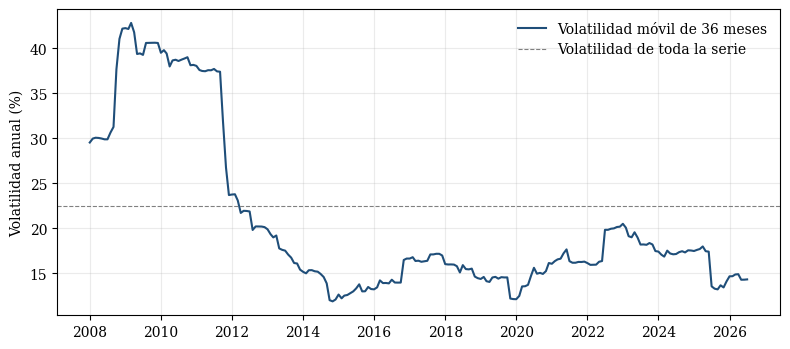

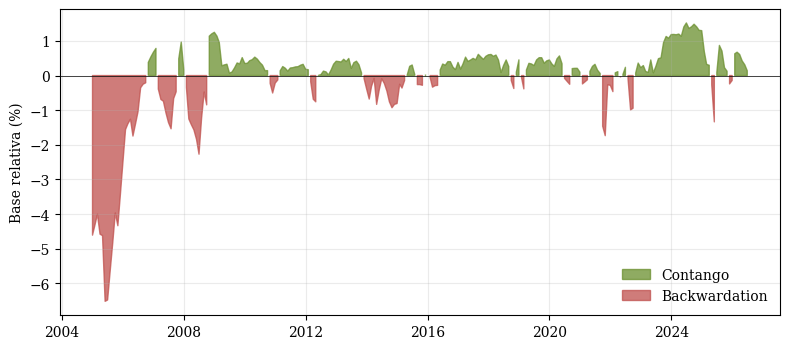

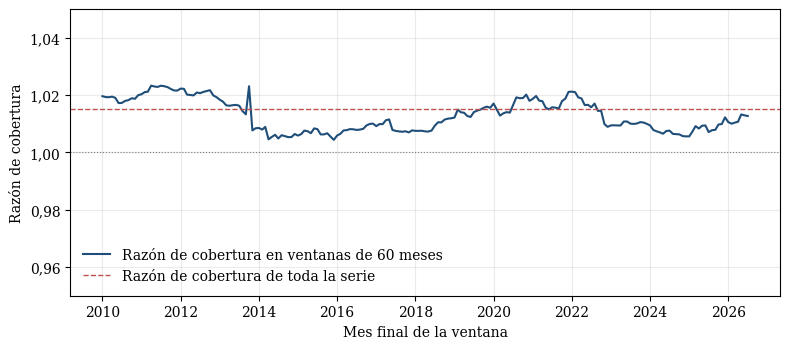

In [9]:
# ==== APARTADO 4.2.3: VOLATILIDAD, BASE Y RAZÓN DE COBERTURA ====
# Celda independiente: carga los datos desde GitHub. Produce las Figuras 4 a 6 y la Tabla 10.
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

ARCHIVO_MENSUAL = "https://raw.githubusercontent.com/vicenteyanezreinoso01-spec/tesis_mineria/main/datos/Precio_cobre_mensual_1960_2026.xlsx"

# --- Datos: promedios mensuales del precio contado y a tres meses (apartado 3.3.1) ---
cf = pd.read_excel(ARCHIVO_MENSUAL, sheet_name="Contado y futuro 2005-2026")
cf.columns = ["mes", "P_cent", "F_cent", "dias"]
cf.index = pd.PeriodIndex(cf["mes"], freq="M")
cf = cf.loc[:"2026-07"]
m = pd.DataFrame({"P": cf["P_cent"] / 100, "F": cf["F_cent"] / 100})   # US$/lb
r  = np.log(m["P"]).diff().dropna()     # ecuación (1), contado
rf = np.log(m["F"]).diff().dropna()     # ecuación (1), futuro a tres meses
QM = 226151 / 20 / 12                   # t por mes
P0, F0 = m["P"].iloc[-1], m["F"].iloc[-1]

# --- B1. Volatilidad móvil de 36 meses ---
vol36 = r.rolling(36).std().dropna() * np.sqrt(12)
B1 = pd.Series({"Volatilidad 36m mínima (%)": vol36.min() * 100, "Mes del mínimo": str(vol36.idxmin()),
                "Volatilidad 36m máxima (%)": vol36.max() * 100, "Mes del máximo": str(vol36.idxmax()),
                "Volatilidad 36m julio 2026 (%)": vol36.iloc[-1] * 100,
                "Volatilidad anual de toda la serie (%)": r.std() * np.sqrt(12) * 100})
print("=== B1. VOLATILIDAD MÓVIL 36 MESES ===");  print(B1.to_string())

# --- B2. Base relativa (F - P) / P ---
base = (m["F"] - m["P"]) / m["P"]
B2 = pd.Series({"Base relativa media (%)": base.mean() * 100,
                "Base relativa mínima (%)": base.min() * 100, "Mes del mínimo": str(base.idxmin()),
                "Base relativa máxima (%)": base.max() * 100, "Mes del máximo": str(base.idxmax()),
                "Desv. estándar base relativa (%)": base.std() * 100,
                "Meses en contango (%)": (base > 0).mean() * 100,
                "Meses en backwardation (%)": (base < 0).mean() * 100,
                "Base relativa julio 2026 (%)": base.iloc[-1] * 100})
print("\n=== B2. BASE RELATIVA ===");  print(B2.to_string())

# --- B3. Razón de cobertura de mínima varianza, ecuación (7) ---
reg = sm.OLS(r.values, sm.add_constant(rf.values)).fit()
H_STAR = reg.params[1]
B3 = pd.Series({"Correlación rendimientos contado-futuro": np.corrcoef(r, rf)[0, 1],
                "h* (pendiente)": H_STAR, "Error estándar de h*": reg.bse[1],
                "IC 95% inferior": reg.conf_int()[1, 0], "IC 95% superior": reg.conf_int()[1, 1],
                "Efectividad (R², %)": reg.rsquared * 100,
                "Toneladas en futuros por mes": H_STAR * QM * P0 / F0,
                "Contratos de 25 t por mes": H_STAR * QM * P0 / F0 / 25})
print("\n=== B3. RAZÓN DE COBERTURA (ecuación 7) ===");  print(B3.to_string())

# --- B4. Estabilidad: misma regresión en ventanas móviles de 60 meses ---
filas = []
for i in range(60, len(r) + 1):
    y, x = r.iloc[i-60:i], rf.iloc[i-60:i]
    f = sm.OLS(y.values, sm.add_constant(x.values)).fit()
    filas.append((r.index[i-1], f.params[1], f.rsquared))
mov = pd.DataFrame(filas, columns=["fin", "h", "R2"]).set_index("fin")
B4 = pd.Series({"Número de ventanas": len(mov),
                "h* mínimo": mov["h"].min(), "Ventana que termina en (mín.)": str(mov["h"].idxmin()),
                "h* máximo": mov["h"].max(), "Ventana que termina en (máx.)": str(mov["h"].idxmax()),
                "h* promedio": mov["h"].mean(), "h* última ventana (2021-2026)": mov["h"].iloc[-1],
                "R² mínimo (%)": mov["R2"].min() * 100, "R² máximo (%)": mov["R2"].max() * 100,
                "Ventanas con h* entre 0,95 y 1,05 (%)": mov["h"].between(0.95, 1.05).mean() * 100})
print("\n=== B4. ESTABILIDAD DE h* (ventanas de 60 meses) ===");  print(B4.to_string())

# --- Figuras (sin título; el título va en la tesis) ---
plt.rcParams.update({"font.family": "serif", "font.size": 10})
AZ, RO, VE = "#1f4e79", "#c0504d", "#6a8f2e"

fig, ax = plt.subplots(figsize=(8, 3.6))                       # Figura 4
ax.plot(vol36.index.to_timestamp(), vol36 * 100, color=AZ, lw=1.5, label="Volatilidad móvil de 36 meses")
ax.axhline(r.std() * np.sqrt(12) * 100, color="gray", ls="--", lw=0.8, label="Volatilidad de toda la serie")
ax.set_ylabel("Volatilidad anual (%)"); ax.legend(frameon=False); ax.grid(alpha=.25)
plt.tight_layout(); plt.savefig("figura4_volatilidad36.png", dpi=300); plt.show()

fig, ax = plt.subplots(figsize=(8, 3.6))                       # Figura 5
t = base.index.to_timestamp()
ax.fill_between(t, base * 100, 0, where=base > 0, color=VE, alpha=.75, label="Contango")
ax.fill_between(t, base * 100, 0, where=base < 0, color=RO, alpha=.75, label="Backwardation")
ax.axhline(0, color="k", lw=0.5); ax.set_ylabel("Base relativa (%)"); ax.legend(frameon=False, loc="lower right"); ax.grid(alpha=.25)
plt.tight_layout(); plt.savefig("figura5_base_relativa.png", dpi=300); plt.show()

fig, ax = plt.subplots(figsize=(8, 3.6))                       # Figura 6
ax.plot(mov.index.to_timestamp(), mov["h"], color=AZ, lw=1.5, label="Razón de cobertura en ventanas de 60 meses")
ax.axhline(H_STAR, color=RO, ls="--", lw=1, label="Razón de cobertura de toda la serie")
ax.axhline(1, color="gray", ls=":", lw=0.8)
ax.set_ylim(0.95, 1.05)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.2f}".replace(".", ",")))
ax.set_ylabel("Razón de cobertura"); ax.set_xlabel("Mes final de la ventana"); ax.legend(frameon=False, loc="lower left"); ax.grid(alpha=.25)
plt.tight_layout(); plt.savefig("figura6_hstar_movil.png", dpi=300); plt.show()


## 3. Modelo y escenarios de precio (apartado 4.3)

- **C1–C3:** comparación de los modelos ARMA(p,q) por BIC, coeficientes y diagnóstico del AR(1) (Figuras 7 y 8; Tablas 11, 12 y 13).
- **C4:** comparación fuera de muestra con el paseo aleatorio: error de pronóstico de la variación a 12 meses desde enero de 2016.
- **C5:** efecto del promedio mensual sobre la persistencia, con el precio del último día hábil de cada mes (Tabla 14).
- **D1–D3:** calibración, generación de los 10.000 escenarios por remuestreo de residuos y validación frente a la serie histórica (Figuras 9 y 10; Tablas 15 y 16).

In [ ]:
# ==== APARTADO 4.3: MODELO Y ESCENARIOS DE PRECIO ====
# Celda independiente: carga los datos desde GitHub y ejecuta todo lo necesario.
# La validación fuera de muestra tarda entre 1 y 2 minutos.
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from matplotlib.ticker import FuncFormatter
warnings.simplefilter("ignore")
import logging; logging.getLogger("statsmodels").setLevel(logging.ERROR)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

ARCHIVO_MENSUAL = "https://raw.githubusercontent.com/vicenteyanezreinoso01-spec/tesis_mineria/main/datos/Precio_cobre_mensual_1960_2026.xlsx"
ARCHIVO_DIARIO  = "https://raw.githubusercontent.com/vicenteyanezreinoso01-spec/tesis_mineria/main/datos/FUENTE%20PRINCIPAL%20-%20Cochilco%20-%20Cotizaciones%20contado%20y%20futuro%20diaria%202005-2026.xls"
H, N, SEED = 12, 10_000, 2026

# --- Datos (igual que en las partes anteriores) ---
cf = pd.read_excel(ARCHIVO_MENSUAL, sheet_name="Contado y futuro 2005-2026")
cf.columns = ["mes", "P_cent", "F_cent", "dias"]
cf.index = pd.PeriodIndex(cf["mes"], freq="M")
cf = cf.loc[:"2026-07"]
m = pd.DataFrame({"P": cf["P_cent"] / 100, "F": cf["F_cent"] / 100})   # US$/lb
lp = np.log(m["P"]); r = lp.diff().dropna()          # ecuación (1)
w12 = lp.diff(12).dropna()                           # variación a 12 meses
base = ((m["F"] - m["P"]) / m["P"]).values           # base relativa histórica
P0 = m["P"].iloc[-1]

# Precio del último día hábil de cada mes (serie diaria)
MESES = {"ene":1,"feb":2,"mar":3,"abr":4,"may":5,"jun":6,"jul":7,"ago":8,"sep":9,"oct":10,"nov":11,"dic":12}
d = pd.read_excel(ARCHIVO_DIARIO, sheet_name="Cobre y otros metales", header=None, skiprows=3)
d = d.iloc[:, [0, 5]]; d.columns = ["f", "P"]
d["f"] = d["f"].astype(str).str.strip()
d = d[d["f"].str.match(r"\d{2}-[a-z]{3}-\d{4}")].copy()
d["fecha"] = pd.to_datetime(d["f"].apply(lambda s: f"{s[7:]}-{MESES[s[3:6]]:02d}-{s[:2]}"))
d["P"] = d["P"].astype(float); d = d[d["P"] > 0].set_index("fecha")
fin_mes = d["P"].groupby(d.index.to_period("M")).last().loc["2005-01":"2026-07"] / 100
r_fin = np.log(fin_mes).diff().dropna()

# =====================================================================
# C. SELECCIÓN DEL MODELO (4.3.1)
# =====================================================================
# C1. Los 16 modelos ARMA(p,q) con p, q entre 0 y 3, ecuación (8)
filas, modelos = [], {}
for p in range(4):
    for q in range(4):
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            f = ARIMA(r.values, order=(p, 0, q), trend="c").fit()
        modelos[(p, q)] = f
        filas.append({"Modelo": f"ARMA({p},{q})", "p": p, "q": q, "Parámetros": p + q + 1, "BIC": f.bic})
tabla_bic = pd.DataFrame(filas).sort_values("BIC").reset_index(drop=True)
tabla_bic["Diferencia con el mejor"] = tabla_bic["BIC"] - tabla_bic["BIC"].iloc[0]
P_SEL, Q_SEL = int(tabla_bic.loc[0, "p"]), int(tabla_bic.loc[0, "q"])
mod = modelos[(P_SEL, Q_SEL)]
print("=== C1. COMPARACIÓN DE LOS 16 MODELOS POR BIC (menor es mejor) ===")
print(tabla_bic.drop(columns=["p", "q"]).to_string(index=False))
print(f"\nPaseo aleatorio ARMA(0,0): BIC = {modelos[(0,0)].bic:.2f}")

# C2. Coeficientes del modelo seleccionado
coef = pd.DataFrame({"Coeficiente": mod.params, "Error estándar": mod.bse, "Valor p": mod.pvalues},
                    index=mod.model.param_names)
print(f"\n=== C2. COEFICIENTES DEL MODELO SELECCIONADO: ARMA({P_SEL},{Q_SEL}) ===")
print("(const = media mensual del proceso; ar.L1 = φ; sigma2 = varianza de las innovaciones)")
print(coef.to_string())

# C3. Diagnóstico de residuos
resid = mod.resid[max(P_SEL, Q_SEL):]
lb = acorr_ljungbox(resid, lags=[12], model_df=P_SEL + Q_SEL)
arch = het_arch(resid, nlags=12)
diag = pd.DataFrame({"Estadístico": [lb["lb_stat"].iloc[0], arch[0]], "Valor p": [lb["lb_pvalue"].iloc[0], arch[1]]},
                    index=["Ljung-Box 12 rezagos (residuos)", "ARCH-LM 12 rezagos (residuos)"])
print("\n=== C3. DIAGNÓSTICO DE LOS RESIDUOS ===");  print(diag.to_string())
print("\nLjung-Box de los residuos en los 8 modelos con menor BIC (¿algún modelo más complejo lo corrige?):")
for _, fila in tabla_bic.head(8).iterrows():
    pp, qq = int(fila["p"]), int(fila["q"]); rr = modelos[(pp, qq)].resid[max(pp, qq):]
    print(f"  {fila['Modelo']}: valor p = {acorr_ljungbox(rr, lags=[12], model_df=pp + qq)['lb_pvalue'].iloc[0]:.3f}")

# C4. Comparación fuera de muestra con el paseo aleatorio (variación a 12 meses, desde enero 2016)
print("\nValidación fuera de muestra en curso (1 a 2 minutos)...")
inicio = list(r.index).index(pd.Period("2016-01", "M"))
err = {"Modelo seleccionado": [], "Paseo aleatorio": []}
for o in range(inicio, len(r) - H + 1):
    real = r.values[o:o + H].sum()
    for nombre, orden in (("Modelo seleccionado", (P_SEL, 0, Q_SEL)), ("Paseo aleatorio", (0, 0, 0))):
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            pron = ARIMA(r.values[:o], order=orden, trend="c").fit().forecast(H).sum()
        err[nombre].append(pron - real)
oos = pd.Series({k: np.sqrt(np.mean(np.square(v))) for k, v in err.items()})
print("=== C4. ERROR DE PRONÓSTICO A 12 MESES (RMSE, variación logarítmica) ===")
print(f"Número de pronósticos: {len(err['Paseo aleatorio'])}");  print(oos.to_string())
print(f"Diferencia relativa: {(oos.iloc[0] / oos.iloc[1] - 1) * 100:.2f}%")

# C5. Efecto del promedio mensual
mod_fin = ARIMA(r_fin.values, order=(P_SEL, 0, Q_SEL), trend="c").fit()
rw_fin = ARIMA(r_fin.values, order=(0, 0, 0), trend="c").fit()
efecto = pd.DataFrame({
    "Autocorrelación 1": [r.autocorr(1), r_fin.autocorr(1)],
    "Coeficiente φ": [mod.params[1], mod_fin.params[1]],
    "Valor p de φ": [mod.pvalues[1], mod_fin.pvalues[1]],
    "BIC paseo aleatorio": [modelos[(0, 0)].bic, rw_fin.bic],
    "BIC modelo seleccionado": [mod.bic, mod_fin.bic],
    "Desv. estándar mensual (%)": [r.std() * 100, r_fin.std() * 100]},
    index=["Promedio mensual", "Último día hábil del mes"])
print("\n=== C5. EFECTO DEL PROMEDIO MENSUAL ===");  print(efecto.T.to_string())

# =====================================================================
# D. GENERACIÓN Y VALIDACIÓN DE ESCENARIOS (4.3.2)
# =====================================================================
MU = mod.params[0]
PHI = mod.arparams if P_SEL else np.array([])
LAM = mod.maparams if Q_SEL else np.array([])
EPS = resid - resid.mean()                       # residuos históricos centrados

def simular(escala=1.0, seed=SEED):
    """Ecuación (8): N trayectorias de 12 rendimientos sorteando residuos históricos."""
    rng = np.random.default_rng(seed)
    e = rng.choice(EPS, (N, H)) * escala
    p, q = len(PHI), len(LAM)
    r_prev = np.tile(r.values[-p:] if p else np.empty(0), (N, 1))
    e_prev = np.tile(EPS[-q:] if q else np.empty(0), (N, 1))
    out = np.empty((N, H))
    for t in range(H):
        rt = MU + e[:, t]
        for i in range(p): rt += PHI[i] * (r_prev[:, -1 - i] - MU)
        for j in range(q): rt += LAM[j] * e_prev[:, -1 - j]
        out[:, t] = rt
        if p: r_prev = np.column_stack([r_prev[:, 1:], rt])
        if q: e_prev = np.column_stack([e_prev[:, 1:], e[:, t]])
    return out

def a_precios(rets, p0):
    """Ecuación (9) y ajuste para que el precio esperado de cada mes sea P0."""
    P = p0 * np.exp(np.cumsum(rets, axis=1))
    factor = p0 / P.mean(axis=0)
    return P * factor, factor

sd12 = lambda s: np.log(a_precios(simular(s), 1.0)[0][:, -1]).std()

# D1. Calibración de la dispersión a 12 meses
SD_HIST = w12.std(); sd_sin = sd12(1.0)
if sd_sin > SD_HIST:
    lo, hi = 0.3, 1.0
    for _ in range(40):
        mid = (lo + hi) / 2
        lo, hi = (lo, mid) if sd12(mid) > SD_HIST else (mid, hi)
    ESCALA = (lo + hi) / 2
else:
    ESCALA = 1.0
print("\n=== D1. CALIBRACIÓN ===")
print(pd.Series({"Dispersión histórica a 12 meses": SD_HIST, "Dispersión simulada sin calibrar": sd_sin,
                 "Factor de escala aplicado": ESCALA}).to_string())

# D2. Escenarios: 10.000 trayectorias de 12 meses, precio a tres meses con la ecuación (10)
P_sim, factor = a_precios(simular(ESCALA), P0)
F_sim = P_sim * (1 + np.random.default_rng(SEED + 1).choice(base, P_sim.shape))
print("\n=== D2. ESCENARIOS ===")
print(f"Escenarios: {N:,} x {H} meses | semilla {SEED}")
print(f"Factor de ajuste del precio esperado: mín {factor.min():.4f}, máx {factor.max():.4f}")
print(f"Sin el ajuste, el precio medio del mes 12 sería {(1 / factor[-1] - 1) * 100:.1f}% superior a P0")
pct = pd.DataFrame({f"Mes {t}": np.percentile(P_sim[:, t - 1], [5, 25, 50, 75, 95]).tolist() + [P_sim[:, t - 1].mean()]
                    for t in (1, 3, 6, 12)}, index=["P5", "P25", "Mediana", "P75", "P95", "Media"])
print("Precio contado simulado (US$/lb):");  print(pct.to_string())

# D3. Validación frente a la serie histórica
rs = np.diff(np.log(np.column_stack([np.full(N, P0), P_sim])), axis=1)
v12 = np.log(P_sim[:, -1] / P0)
valid = pd.DataFrame({
    "Histórico": [SD_HIST, (w12 - w12.mean()).quantile(.05), r.autocorr(1), stats.kurtosis(r)],
    "Simulado": [v12.std(), np.quantile(v12 - v12.mean(), .05),
                 np.corrcoef(rs[:, 1:].ravel(), rs[:, :-1].ravel())[0, 1], stats.kurtosis(rs.ravel())]},
    index=["Desv. estándar variación 12 meses", "Percentil 5 variación 12 meses, centrada",
           "Autocorrelación 1 de los rendimientos", "Exceso de curtosis de los rendimientos"])
print("\n=== D3. VALIDACIÓN DE LOS ESCENARIOS ===");  print(valid.to_string())

# --- Figuras (sin título; el título va en la tesis) ---
plt.rcParams.update({"font.family": "serif", "font.size": 10})
AZ, RO, GR = "#1f4e79", "#c0504d", "#9a9a9a"
coma = lambda eje, dec=2: eje.set_major_formatter(FuncFormatter(lambda v, p: f"{v:.{dec}f}".replace(".", ",").replace("-", "−")))

# Correlogramas al estilo Box-Jenkins: barras con punta redonda y límites de significancia
from statsmodels.tsa.stattools import acf, pacf
K = 24
def correlograma(ax, valores, n, nombre):
    rez = np.arange(1, K + 1); b = 1.96 / np.sqrt(n)
    ax.vlines(rez, 0, valores, color=AZ, lw=1.4)
    ax.plot(rez, valores, "o", color=AZ, ms=4.5)
    ax.axhline(0, color="k", lw=.6)
    ax.axhline(b, color=RO, ls="--", lw=.9); ax.axhline(-b, color=RO, ls="--", lw=.9)
    ax.set_xlim(0.3, K + 0.7); ax.set_ylim(-0.3, 0.5); ax.set_xticks([1, 6, 12, 18, 24])
    ax.set_ylabel(nombre); coma(ax.yaxis, 1); ax.grid(alpha=.2)

# Figura 7 (4.3.1): autocorrelación simple y parcial de los rendimientos
fig, ax = plt.subplots(2, 1, figsize=(8, 5.2), sharex=True)
correlograma(ax[0], acf(r, nlags=K)[1:], len(r), "Autocorrelación simple")
correlograma(ax[1], pacf(r, nlags=K, method="ywm")[1:], len(r), "Autocorrelación parcial")
ax[0].plot([], [], color=RO, ls="--", lw=.9, label="Límites de significancia al 95%"); ax[0].legend(frameon=False, loc="upper right")
ax[1].set_xlabel("Rezago (meses)")
plt.tight_layout(); plt.savefig("figura7_correlograma.png", dpi=300); plt.show()

# Figura 8 (4.3.1): autocorrelación de los residuos del modelo seleccionado
fig, ax = plt.subplots(figsize=(8, 3.0))
correlograma(ax, acf(resid, nlags=K)[1:], len(resid), "Autocorrelación simple"); ax.set_xlabel("Rezago (meses)")
plt.tight_layout(); plt.savefig("figura8_residuos.png", dpi=300); plt.show()

# Figura 9 (4.3.2): precio histórico reciente y escenarios simulados
hist = m["P"].loc["2024-08":]          # últimos dos años
fechas = pd.period_range("2026-07", periods=H + 1, freq="M").to_timestamp()
Pc = np.column_stack([np.full(N, P0), P_sim])
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(hist.index.to_timestamp(), hist, color="k", lw=1.5, label="Precio histórico")
idx = np.argsort(Pc[:, -1])[np.linspace(150, N - 150, 30).astype(int)]   # 30 escenarios repartidos en toda la distribución
for i in idx: ax.plot(fechas, Pc[i], color=GR, lw=.6, alpha=.7)
ax.plot([], [], color=GR, lw=.8, label="Escenarios simulados (30 de 10.000)")
ax.plot(fechas, np.median(Pc, 0), color=AZ, lw=2, label="Mediana de los escenarios")
ax.plot(fechas, np.percentile(Pc, 5, 0), color=RO, lw=2, ls="--", label="Percentil 5 de los escenarios")
ax.axvline(fechas[0], color="k", ls=":", lw=.8)
ax.text(fechas[0], ax.get_ylim()[1] * .97, "  inicio del horizonte", fontsize=8, va="top")
tk = pd.period_range("2024-07", "2027-07", freq="6M").to_timestamp()
AB = ["ene","feb","mar","abr","may","jun","jul","ago","sep","oct","nov","dic"]
ax.set_xticks(tk); ax.set_xticklabels([f"{AB[t.month-1]} {t.year}" for t in tk])
ax.set_ylabel("Precio (US$/lb)"); coma(ax.yaxis, 1); ax.legend(frameon=False, fontsize=8.5, loc="upper left"); ax.grid(alpha=.25)
plt.tight_layout(); plt.savefig("figura9_escenarios.png", dpi=300); plt.show()

# Figura 10 (4.3.2): validación, variación a 12 meses histórica vs simulada
xs = np.linspace(-90, 90, 500)
h_c = (w12 - w12.mean()).values * 100; s_c = (v12 - v12.mean()) * 100
fig, ax = plt.subplots(figsize=(8, 3.6))
for datos, col, nom in ((h_c, RO, "Ventanas históricas de doce meses"), (s_c, AZ, "Escenarios simulados")):
    ax.plot(xs, stats.gaussian_kde(datos)(xs), color=col, lw=2, label=nom)
    p5 = np.percentile(datos, 5)
    ax.axvline(p5, color=col, ls="--", lw=1)
    ax.text(p5 - 2, ax.get_ylim()[1] * (.85 if col == RO else .65), f"P5: {p5:.0f}%".replace("-", "−"), color=col, ha="right", fontsize=9)
ax.set_xlabel("Variación logarítmica del precio a doce meses, respecto de su promedio (%)"); ax.set_ylabel("Densidad")
coma(ax.yaxis, 3); ax.legend(frameon=False, loc="upper right"); ax.grid(alpha=.25)
plt.tight_layout(); plt.savefig("figura10_validacion.png", dpi=300); plt.show()


=== C1. COMPARACIÓN DE LOS 16 MODELOS POR BIC (menor es mejor) ===
   Modelo  Parámetros       BIC  Diferencia con el mejor
ARMA(1,0)           2 -705.2748                   0.0000
ARMA(0,1)           2 -700.5224                   4.7523
ARMA(0,2)           3 -700.3508                   4.9239
ARMA(2,0)           3 -699.8148                   5.4599
ARMA(1,1)           3 -699.7953                   5.4794
ARMA(0,3)           4 -694.9841                  10.2906
ARMA(3,0)           4 -694.9347                  10.3400
ARMA(1,2)           4 -694.8866                  10.3882
ARMA(2,1)           4 -694.1948                  11.0799
ARMA(3,1)           5 -692.1283                  13.1465
ARMA(2,2)           5 -689.5803                  15.6944
ARMA(1,3)           5 -689.2478                  16.0270
ARMA(3,3)           7 -686.0913                  19.1834
ARMA(3,2)           6 -684.1475                  21.1272
ARMA(2,3)           6 -683.9757                  21.2991
ARMA(0,0)           1

## 4. Exposición de los ingresos sin cobertura (apartado 4.4)

- **E1–E2:** ingreso de los 12 meses en cada escenario, ecuación (2), ingreso en riesgo y probabilidad de caer bajo el umbral, ecuaciones (5) y (11) (Tabla 17; Figura 11).
- **E3:** probabilidad bajo umbrales alternativos (se informa en la Tabla 24).

In [ ]:
# ==== APARTADO 4.4: EXPOSICIÓN DE LOS INGRESOS SIN COBERTURA ====
# Celda independiente: carga los datos, regenera los mismos 10.000 escenarios del 4.3
# (mismo modelo AR(1), misma calibración y misma semilla) y calcula la exposición.
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from matplotlib.ticker import FuncFormatter
warnings.simplefilter("ignore")
import logging; logging.getLogger("statsmodels").setLevel(logging.ERROR)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

ARCHIVO_MENSUAL = "https://raw.githubusercontent.com/vicenteyanezreinoso01-spec/tesis_mineria/main/datos/Precio_cobre_mensual_1960_2026.xlsx"
H, N, SEED = 12, 10_000, 2026
QM = 226151 / 20 / 12          # t de cobre fino por mes (≈ 942)
K_LB = 2204.6223               # libras por tonelada (k)
ALFA, UMBRAL = 0.05, 0.80      # nivel del ingreso en riesgo y umbral de ingreso
q = QM * K_LB                  # libras vendidas por mes

# --- Datos ---
cf = pd.read_excel(ARCHIVO_MENSUAL, sheet_name="Contado y futuro 2005-2026")
cf.columns = ["mes", "P_cent", "F_cent", "dias"]
cf.index = pd.PeriodIndex(cf["mes"], freq="M")
cf = cf.loc[:"2026-07"]
m = pd.DataFrame({"P": cf["P_cent"] / 100, "F": cf["F_cent"] / 100})   # US$/lb
lp = np.log(m["P"]); r = lp.diff().dropna(); w12 = lp.diff(12).dropna()
P0 = m["P"].iloc[-1]

# --- Escenarios (idénticos a los del 4.3) ---
mod = ARIMA(r.values, order=(1, 0, 0), trend="c").fit()      # AR(1) seleccionado en el 4.3.1
MU, PHI = mod.params[0], mod.params[1]
resid = mod.resid[1:]; EPS = resid - resid.mean()

def simular(escala=1.0, seed=SEED):
    e = np.random.default_rng(seed).choice(EPS, (N, H)) * escala
    r_prev = np.full(N, r.values[-1]); out = np.empty((N, H))
    for t in range(H):
        rt = MU + PHI * (r_prev - MU) + e[:, t]; out[:, t] = rt; r_prev = rt
    return out

def a_precios(rets, p0):
    P = p0 * np.exp(np.cumsum(rets, axis=1)); return P * (p0 / P.mean(axis=0))

sd12 = lambda s: np.log(a_precios(simular(s), 1.0)[:, -1]).std()
lo, hi = 0.3, 1.0
for _ in range(40):
    mid = (lo + hi) / 2; lo, hi = (lo, mid) if sd12(mid) > w12.std() else (mid, hi)
ESCALA = (lo + hi) / 2
P_sim = a_precios(simular(ESCALA), P0)
print(f"Control: factor de escala = {ESCALA:.4f} (debe ser 0,8745) | P5 del precio en el mes 12 = {np.percentile(P_sim[:, -1], 5):.4f} (debe ser 3,6443)")

# =====================================================================
# E1. Ingreso de cada escenario, ecuación (2), y medidas de exposición, ecuaciones (5) y (11)
# =====================================================================
I = (q * P_sim).sum(axis=1)                 # ingreso de los 12 meses en cada escenario (US$)
I_REF = 12 * q * P0                         # ingreso si el precio se mantuviera en P0
UMB = UMBRAL * I_REF                        # ecuación (11)
E_I = I.mean(); Q_A = np.quantile(I, ALFA); IER = E_I - Q_A

E1 = pd.Series({
    "Ingreso de referencia, precio constante en P0 (MM US$)": I_REF / 1e6,
    "Ingreso esperado E[I] (MM US$)": E_I / 1e6,
    "Percentil 5 del ingreso (MM US$)": Q_A / 1e6,
    "Ingreso en riesgo al 5%, ecuación (5) (MM US$)": IER / 1e6,
    "Ingreso en riesgo como % del ingreso esperado": IER / E_I * 100,
    "Umbral de ingreso, ecuación (11) (MM US$)": UMB / 1e6,
    "Probabilidad de caer bajo el umbral, caída > 20% (%)": (I < UMB).mean() * 100})
print("\n=== E1. EXPOSICIÓN DE LOS INGRESOS SIN COBERTURA ===");  print(E1.to_string())

# E2. Distribución del ingreso
pcts = [1, 5, 10, 25, 50, 75, 90, 95, 99]
E2 = pd.Series({**{f"Percentil {p} (MM US$)": np.percentile(I, p) / 1e6 for p in pcts},
                "Mínimo (MM US$)": I.min() / 1e6, "Máximo (MM US$)": I.max() / 1e6,
                "Desv. estándar (MM US$)": I.std() / 1e6,
                "Desv. estándar como % del ingreso esperado": I.std() / E_I * 100})
print("\n=== E2. DISTRIBUCIÓN DEL INGRESO DE LOS 12 MESES ===");  print(E2.to_string())

# E3. Referencia para el análisis de sensibilidad del 4.6 (umbrales alternativos)
E3 = pd.Series({f"Probabilidad de caída > {int(c*100)}% (%)": (I < (1 - c) * I_REF).mean() * 100 for c in (0.10, 0.20, 0.30)})
print("\n=== E3. UMBRALES ALTERNATIVOS (se informan en el 4.6) ===");  print(E3.to_string())

# =====================================================================
# Figura 11: distribución del ingreso sin cobertura
# =====================================================================
plt.rcParams.update({"font.family": "serif", "font.size": 10})
AZ, RO, GR = "#1f4e79", "#c0504d", "#7f7f7f"
miles = FuncFormatter(lambda v, p: f"{v:,.0f}".replace(",", "."))
Im = I / 1e6
fig, ax = plt.subplots(figsize=(8, 4))
cnt, bordes, barras = ax.hist(Im, bins=70, color=AZ, alpha=.75, edgecolor="white", lw=.3)
for b, izq in zip(barras, bordes[:-1]):
    if izq < Q_A / 1e6: b.set_facecolor(RO)
ymax = cnt.max()
ax.axvline(E_I / 1e6, color="k", lw=1.5, label=f"Ingreso esperado: {E_I/1e6:.1f}".replace(".", ","))
ax.axvline(Q_A / 1e6, color=RO, lw=1.5, ls="--", label=f"Percentil 5: {Q_A/1e6:.1f}".replace(".", ","))
ax.axvline(UMB / 1e6, color=GR, lw=1.2, ls=":", label=f"Umbral de caída de 20%: {UMB/1e6:.1f}".replace(".", ","))
ax.bar([0], [0], color=RO, alpha=.75, label="5% de escenarios más desfavorables")
ax.annotate("", xy=(Q_A / 1e6, ymax * 1.10), xytext=(E_I / 1e6, ymax * 1.10), arrowprops=dict(arrowstyle="<->", color="k", lw=1))
ax.text((Q_A + E_I) / 2e6, ymax * 1.13, f"Ingreso en riesgo: {IER/1e6:.1f}".replace(".", ","), ha="center", fontsize=9)
ax.set_ylim(0, ymax * 1.25); ax.legend(frameon=False, fontsize=8.5, loc="upper right")
ax.set_xlabel("Ingreso de agosto de 2026 a julio de 2027 (millones de US$)"); ax.set_ylabel("Número de escenarios")
ax.xaxis.set_major_formatter(miles); ax.yaxis.set_major_formatter(miles); ax.grid(alpha=.2)
ax.set_xlim(np.percentile(Im, 0.05), np.percentile(Im, 99.8))
plt.tight_layout(); plt.savefig("figura11_ingreso.png", dpi=300); plt.show()


## 5. Desempeño de las estrategias de cobertura (apartado 4.5)

- **F1–F2:** precios de ejercicio, primas, ecuación (12), y precio de ejercicio de la call del collar, ecuación (13) (Tablas 18 y 19).
- **F3–F5:** ingreso con cada estrategia, ecuación (3), reducción del ingreso en riesgo, costo en ingreso esperado, liquidez comprometida y eficiencia, ecuaciones (5), (6), (14) y (15) (Tablas 20 y 21; Figuras 12 y 13).

In [ ]:
# ==== APARTADO 4.5: DESEMPEÑO DE LAS ESTRATEGIAS DE COBERTURA ====
# Celda independiente: regenera los mismos escenarios del 4.3 y evalúa las 7 estrategias.
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA
from matplotlib.ticker import FuncFormatter
warnings.simplefilter("ignore")
import logging; logging.getLogger("statsmodels").setLevel(logging.ERROR)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}"); pd.set_option("display.width", 220)

ARCHIVO_MENSUAL = "https://raw.githubusercontent.com/vicenteyanezreinoso01-spec/tesis_mineria/main/datos/Precio_cobre_mensual_1960_2026.xlsx"
H, N, SEED = 12, 10_000, 2026
QM = 226151 / 20 / 12; K_LB = 2204.6223; q = QM * K_LB     # t/mes, lb/t, lb/mes
ALFA, UMBRAL, KP_FRAC, R_F = 0.05, 0.80, 0.90, 0.0405
T_M = np.arange(1, H + 1) / 12; DESC = np.exp(-R_F * T_M)   # factor de valor presente de cada mes

# --- Datos ---
cf = pd.read_excel(ARCHIVO_MENSUAL, sheet_name="Contado y futuro 2005-2026")
cf.columns = ["mes", "P_cent", "F_cent", "dias"]
cf.index = pd.PeriodIndex(cf["mes"], freq="M"); cf = cf.loc[:"2026-07"]
m = pd.DataFrame({"P": cf["P_cent"] / 100, "F": cf["F_cent"] / 100})
lp = np.log(m["P"]); r = lp.diff().dropna(); w12 = lp.diff(12).dropna()
rf = np.log(m["F"]).diff().dropna(); base = ((m["F"] - m["P"]) / m["P"]).values
P0, F0 = m["P"].iloc[-1], m["F"].iloc[-1]
H_STAR = sm.OLS(r.values, sm.add_constant(rf.values)).fit().params[1]   # ecuación (7), apartado 4.2.3

# --- Escenarios (idénticos a los del 4.3) ---
mod = ARIMA(r.values, order=(1, 0, 0), trend="c").fit()
MU, PHI = mod.params[0], mod.params[1]; resid = mod.resid[1:]; EPS = resid - resid.mean()
def simular(escala=1.0, seed=SEED):
    e = np.random.default_rng(seed).choice(EPS, (N, H)) * escala
    r_prev = np.full(N, r.values[-1]); out = np.empty((N, H))
    for t in range(H):
        rt = MU + PHI * (r_prev - MU) + e[:, t]; out[:, t] = rt; r_prev = rt
    return out
def a_precios(rets, p0):
    P = p0 * np.exp(np.cumsum(rets, axis=1)); return P * (p0 / P.mean(axis=0))
sd12 = lambda s: np.log(a_precios(simular(s), 1.0)[:, -1]).std()
lo, hi = 0.3, 1.0
for _ in range(40):
    mid = (lo + hi) / 2; lo, hi = (lo, mid) if sd12(mid) > w12.std() else (mid, hi)
P_sim = a_precios(simular((lo + hi) / 2), P0)
F_sim = P_sim * (1 + np.random.default_rng(SEED + 1).choice(base, P_sim.shape))   # ecuación (10)
print(f"Control: P5 del precio en el mes 12 = {np.percentile(P_sim[:, -1], 5):.4f} (debe ser 3,6443) | h* = {H_STAR:.4f}")

# =====================================================================
# F1. Parámetros de las estrategias: primas (ecuación 12) y Kc (ecuación 13)
# =====================================================================
def prima(K, tipo):
    pago = np.maximum(K - P_sim, 0) if tipo == "put" else np.maximum(P_sim - K, 0)
    return DESC * pago.mean(axis=0)                       # una prima por mes de vencimiento
Kp = KP_FRAC * P0; pm = prima(Kp, "put")
lo, hi = P0, 4 * P0
for _ in range(60):                                       # Kc que iguala la suma de primas
    mid = (lo + hi) / 2; lo, hi = (mid, hi) if prima(mid, "call").sum() > pm.sum() else (lo, mid)
Kc = (lo + hi) / 2; cm = prima(Kc, "call")
TH_H = H_STAR * P0 / F0                                   # proporción cubierta con h*

F1 = pd.Series({"P0 (US$/lb)": P0, "F0 (US$/lb)": F0,
                "Kp = 90% de P0 (US$/lb)": Kp, "Kc del collar (US$/lb)": Kc, "Kc como % de P0": Kc / P0 * 100,
                "Suma de primas put, 12 meses (US$/lb)": pm.sum(), "Suma de primas call, 12 meses (US$/lb)": cm.sum(),
                "Costo total put 100% (MM US$)": q * pm.sum() / 1e6, "Costo total put 50% (MM US$)": 0.5 * q * pm.sum() / 1e6,
                "Prima put como % del ingreso esperado": q * pm.sum() / (12 * q * P0) * 100,
                "Proporción cubierta con h* (θ = h*·P0/F0)": TH_H,
                "Toneladas en futuros por mes con h*": TH_H * QM, "Contratos de 25 t por mes con h*": TH_H * QM / 25})
print("\n=== F1. PARÁMETROS DE LAS ESTRATEGIAS ===");  print(F1.to_string())
F2 = pd.DataFrame({"Prima put (US$/lb)": pm, "Prima call (US$/lb)": cm,
                   "Prob. de pago put (%)": (P_sim < Kp).mean(0) * 100, "Prob. de pago call (%)": (P_sim > Kc).mean(0) * 100},
                  index=[f"Mes {i}" for i in range(1, H + 1)])
print("\n=== F2. PRIMAS POR MES DE VENCIMIENTO ===");  print(F2.to_string())

# =====================================================================
# F3. Ingreso con cobertura (ecuación 3) y medidas de cada estrategia (ecuaciones 5, 6, 14 y 15)
# =====================================================================
def medidas(I):
    E = I.mean(); qa = np.quantile(I, ALFA)
    return E, E - qa, (I < UMBRAL * 12 * q * P0).mean()
def liquidez(th, ref):                                     # ecuación (14), por escenario
    abiertos = np.arange(H, 0, -1)                          # meses con posición abierta en el mes t
    return (th * q * abiertos * np.maximum(F_sim - ref, 0)).max(axis=1)

G_fut = F0 - F_sim
G_put = np.maximum(Kp - P_sim, 0) - pm
G_col = np.maximum(Kp - P_sim, 0) - np.maximum(P_sim - Kc, 0) - (pm - cm)
I0 = (q * P_sim).sum(1)
estr = {"Sin cobertura": (I0, np.zeros(N))}
for nom, th in (("50%", 0.5), ("100%", 1.0), ("h*", TH_H)):
    estr[f"Futuros {nom}"] = ((q * (P_sim + th * G_fut)).sum(1), liquidez(th, F0))
for nom, th in (("50%", 0.5), ("100%", 1.0)):
    estr[f"Put {nom}"] = ((q * (P_sim + th * G_put)).sum(1), np.full(N, th * q * pm.sum()))
for nom, th in (("50%", 0.5), ("100%", 1.0)):
    estr[f"Collar {nom}"] = ((q * (P_sim + th * G_col)).sum(1), liquidez(th, Kc))

E0, IER0, PU0 = medidas(I0); filas = {}; INGRESOS = {}
for k, (I, L) in estr.items():
    E, IER, PU = medidas(I); INGRESOS[k] = I
    L95 = np.quantile(L, .95); dIER = IER0 - IER
    filas[k] = {"E[I] (MM)": E / 1e6, "IeR (MM)": IER / 1e6, "IeR % de E[I]": IER / E * 100,
                "P bajo umbral (%)": PU * 100, "ΔIeR (MM)": dIER / 1e6, "ΔIeR (%)": dIER / IER0 * 100,
                "D (MM)": (E0 - E) / 1e6, "Liquidez p95 (MM)": L95 / 1e6,
                "Eficiencia E": dIER / L95 if L95 > 0 else np.nan}
tabla = pd.DataFrame(filas).T
print("\n=== F3. TABLA COMPARATIVA DE LAS ESTRATEGIAS (montos en millones de US$) ===")
print(tabla.to_string())

# F4. Detalle de la liquidez exigida (ecuación 14) en las estrategias con garantías
F4 = pd.DataFrame({k: {"Escenarios que exigen garantías (%)": (estr[k][1] > 0).mean() * 100,
                       "Mediana (MM)": np.median(estr[k][1]) / 1e6, "Percentil 95 (MM)": np.quantile(estr[k][1], .95) / 1e6,
                       "Máximo (MM)": estr[k][1].max() / 1e6}
                   for k in ("Futuros 50%", "Futuros 100%", "Futuros h*", "Collar 50%", "Collar 100%")}).T
print("\n=== F4. DETALLE DE LA LIQUIDEZ EXIGIDA ===");  print(F4.to_string())

# F5. Ordenamientos
print("\n=== F5. ORDEN DE LAS ESTRATEGIAS ===")
print("Por reducción del ingreso en riesgo:", " > ".join(tabla.drop("Sin cobertura")["ΔIeR (%)"].sort_values(ascending=False).index))
print("Por eficiencia:                     ", " > ".join(tabla.drop("Sin cobertura")["Eficiencia E"].sort_values(ascending=False).index))

# =====================================================================
# Figuras (sin título; el título va en la tesis)
# =====================================================================
plt.rcParams.update({"font.family": "serif", "font.size": 10})
GR, RO, AZ, VE = "#9a9a9a", "#c0504d", "#1f4e79", "#6a8f2e"
dec = lambda d: FuncFormatter(lambda v, p: f"{v:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", "."))

# Figura 12: distribución del ingreso con cada instrumento (100%) frente a sin cobertura
fig, axs = plt.subplots(1, 3, figsize=(10, 3.6))          # cada panel con su propia escala vertical
bins = np.linspace(70, 260, 60)
for ax, (k, col) in zip(axs, (("Futuros 100%", RO), ("Put 100%", AZ), ("Collar 100%", VE))):
    ax.hist(I0 / 1e6, bins=bins, color=GR, alpha=.45, label="Sin cobertura")
    ax.hist(INGRESOS[k] / 1e6, bins=bins, color=col, alpha=.75, label=k)
    ax.axvline(np.quantile(I0, ALFA) / 1e6, color="k", ls=":", lw=1)
    ax.axvline(np.quantile(INGRESOS[k], ALFA) / 1e6, color=col, ls="--", lw=1.5)
    ax.set_title(k, fontsize=10); ax.set_xlabel("Ingreso (millones de US$)"); ax.set_xlim(70, 260)
    ax.xaxis.set_major_formatter(dec(0)); ax.yaxis.set_major_formatter(dec(0)); ax.grid(alpha=.2)
axs[0].set_ylabel("Número de escenarios")
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=GR, alpha=.45, label="Sin cobertura"), Patch(color="#555555", alpha=.75, label="Con cobertura"),
                    Line2D([], [], color="k", ls=":", label="Percentil 5 sin cobertura"),
                    Line2D([], [], color="#555555", ls="--", label="Percentil 5 con cobertura")],
           loc="lower center", ncol=4, frameon=False, fontsize=9)
plt.tight_layout(rect=(0, .08, 1, 1)); plt.savefig("figura12_ingreso_estrategias.png", dpi=300); plt.show()

# Figura 13: protección obtenida frente a liquidez comprometida
t = tabla.drop("Sin cobertura")
col = {"Futuros": RO, "Put": AZ, "Collar": VE}
fig, ax = plt.subplots(figsize=(8, 4.2))
for k, f in t.iterrows():
    c = col[k.split()[0]]
    ax.scatter(f["Liquidez p95 (MM)"], f["ΔIeR (%)"], s=70, color=c, zorder=3)
    desp = {"Futuros 100%": (8, 4), "Futuros h*": (8, -12)}.get(k, (8, -3))
    ax.annotate(k, (f["Liquidez p95 (MM)"], f["ΔIeR (%)"]), xytext=desp, textcoords="offset points", fontsize=9)
for nom, c in col.items(): ax.scatter([], [], color=c, s=50, label=nom)
ax.set_xlabel("Liquidez comprometida, percentil 95 (millones de US$)")
ax.set_ylabel("Protección: reducción del\ningreso en riesgo (%)")
ax.set_xlim(0, t["Liquidez p95 (MM)"].max() * 1.25); ax.set_ylim(0, 110)
ax.xaxis.set_major_formatter(dec(0)); ax.legend(frameon=False, loc="lower right"); ax.grid(alpha=.25)
plt.tight_layout(); plt.savefig("figura13_proteccion_liquidez.png", dpi=300); plt.show()


## 6. Análisis de sensibilidad (apartado 4.6)

Modifica un supuesto a la vez según la Tabla 7 (incluido el modelo GARCH(1,1)) y recalcula la exposición y las estrategias (Tablas 22, 23 y 24; Figura 14). Tarda entre 1 y 3 minutos.

In [ ]:
# ==== APARTADO 4.6: ANÁLISIS DE SENSIBILIDAD ====
# Celda independiente. Modifica un supuesto a la vez (Tabla 7)
# y recalcula la exposición y las estrategias.
# Tarda entre 1 y 3 minutos.
import subprocess, sys

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "arch"], check=False)
import warnings

warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA
from arch import arch_model

warnings.simplefilter("ignore")
import logging

logging.getLogger("statsmodels").setLevel(logging.ERROR)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.width", 250)

ARCHIVO_MENSUAL = (
    "https://raw.githubusercontent.com/vicenteyanezreinoso01-spec/tesis_mineria/main/"
    "datos/Precio_cobre_mensual_1960_2026.xlsx"
)
H, N, SEED = 12, 10_000, 2026
QM = 226151 / 20 / 12
K_LB = 2204.6223
q = QM * K_LB
ALFA, UMBRAL, KP_FRAC, R_F = 0.05, 0.80, 0.90, 0.0405
DESC = np.exp(-R_F * np.arange(1, H + 1) / 12)

# --- Datos ---
cf = pd.read_excel(ARCHIVO_MENSUAL, sheet_name="Contado y futuro 2005-2026")
cf.columns = ["mes", "P_cent", "F_cent", "dias"]
cf.index = pd.PeriodIndex(cf["mes"], freq="M")
cf = cf.loc[:"2026-07"]
m = pd.DataFrame({"P": cf["P_cent"] / 100, "F": cf["F_cent"] / 100})
lp = np.log(m["P"])
r = lp.diff().dropna()
w12 = lp.diff(12).dropna()
rf = np.log(m["F"]).diff().dropna()
BASE = ((m["F"] - m["P"]) / m["P"]).values
P0, F0 = m["P"].iloc[-1], m["F"].iloc[-1]
H_STAR = sm.OLS(r.values, sm.add_constant(rf.values)).fit().params[1]
vol36 = r.rolling(36).std().dropna() * np.sqrt(12)
sl = pd.read_excel(
    ARCHIVO_MENSUAL, sheet_name="Serie 1960-2026"
)  # serie larga (solo sensibilidad)
larga = pd.Series(
    sl.iloc[:, 2].values / 100, index=pd.PeriodIndex(sl.iloc[:, 0], freq="M")
).loc["1990-01":"2026-07"]
r_larga = np.log(larga).diff().dropna()


# --- Motor de escenarios (AR(1) del 4.3) ---
def ajustar(serie):
    f = ARIMA(serie.values, order=(1, 0, 0), trend="c").fit()
    e = f.resid[1:]
    return f.params[0], f.params[1], e - e.mean(), e


def simular(r_hist, mu, phi, eps, escala=1.0, n=N, seed=SEED, choques=None):
    e = (
        np.random.default_rng(seed).choice(eps, (n, H)) * escala
        if choques is None
        else choques
    )
    r_prev = np.full(n, r_hist[-1])
    out = np.empty((n, H))
    for t in range(H):
        rt = mu + phi * (r_prev - mu) + e[:, t]
        out[:, t] = rt
        r_prev = rt
    return out


def a_precios(rets):
    P = P0 * np.exp(np.cumsum(rets, axis=1))
    return P * (P0 / P.mean(axis=0))


def calibrar(r_hist, mu, phi, eps, objetivo, n=N):
    sd = lambda s: np.log(a_precios(simular(r_hist, mu, phi, eps, s, n))[:, -1] / P0).std()
    if sd(1.0) <= objetivo:
        return 1.0
    lo, hi = 0.3, 1.0
    for _ in range(40):
        mid = (lo + hi) / 2
        lo, hi = (lo, mid) if sd(mid) > objetivo else (mid, hi)
    return (lo + hi) / 2


def futuros(P, seed=SEED):
    return P * (1 + np.random.default_rng(seed + 1).choice(BASE, P.shape))  # ecuación (10)


MU, PHI, EPS, RESID = ajustar(r)
ESCALA = calibrar(r.values, MU, PHI, EPS, w12.std())
P_base = a_precios(simular(r.values, MU, PHI, EPS, ESCALA))
F_base = futuros(P_base)
print(
    f"Control: P5 del precio en el mes 12 = {np.percentile(P_base[:, -1], 5):.4f} (debe ser 3,6443)"
)


# --- Evaluación de las 7 estrategias (igual que en el 4.5, con opciones de sensibilidad) ---
def evaluar(P, F, kp_frac=KP_FRAC, alfa=ALFA, umbral=UMBRAL, recargo=0.0):
    n = P.shape[0]
    I_REF = 12 * q * P0
    prima = lambda K, tipo: DESC * (
        np.maximum(K - P, 0) if tipo == "put" else np.maximum(P - K, 0)
    ).mean(0)
    Kp = kp_frac * P0
    pm = prima(Kp, "put")
    lo, hi = P0, 4 * P0
    for _ in range(60):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if prima(mid, "call").sum() > pm.sum() else (lo, mid)
    Kc = (lo + hi) / 2
    cm = prima(Kc, "call")
    pm_c = pm * (1 + recargo)  # prima pagada con recargo (solo la put)
    liq = lambda th, ref: (th * q * np.arange(H, 0, -1) * np.maximum(F - ref, 0)).max(axis=1)
    put_pago = np.maximum(Kp - P, 0)
    call_pago = np.maximum(P - Kc, 0)
    neto_col = (pm_c - cm).sum()  # costo neto inicial del collar (cero sin recargo)
    estr = {"Sin cobertura": ((q * P).sum(1), 0.0)}
    for nom, th in (("50%", 0.5), ("100%", 1.0), ("h*", H_STAR * P0 / F0)):
        estr[f"Futuros {nom}"] = (
            (q * (P + th * (F0 - F))).sum(1),
            np.quantile(liq(th, F0), 0.95),
        )
    for nom, th in (("50%", 0.5), ("100%", 1.0)):
        estr[f"Put {nom}"] = ((q * (P + th * (put_pago - pm_c))).sum(1), th * q * pm_c.sum())
        estr[f"Collar {nom}"] = (
            (q * (P + th * (put_pago - call_pago - (pm_c - cm)))).sum(1),
            np.quantile(liq(th, Kc), 0.95) + th * q * max(neto_col, 0),
        )
    filas = {}
    for k, (I, L) in estr.items():
        E = I.mean()
        ier = E - np.quantile(I, alfa)
        filas[k] = {"E": E, "IeR": ier, "PU": (I < umbral * I_REF).mean(), "L": L}
    t = pd.DataFrame(filas).T
    t["RedIeR"] = t.loc["Sin cobertura", "IeR"] - t["IeR"]
    t["RedIeR %"] = t["RedIeR"] / t.loc["Sin cobertura", "IeR"] * 100
    t["D"] = t.loc["Sin cobertura", "E"] - t["E"]
    t["Eficiencia"] = t["RedIeR"] / t["L"].replace(0, np.nan)
    return t, {
        "Kp": Kp,
        "Kc": Kc,
        "Costo put 100% (MM)": q * pm_c.sum() / 1e6,
        "Costo neto collar 100% (MM)": q * neto_col / 1e6,
    }


def orden(t, col):  # orden de los instrumentos dentro de cada proporción
    return {
        th: tuple(
            t.loc[[f"Futuros {th}", f"Put {th}", f"Collar {th}"], col]
            .sort_values(ascending=False)
            .index.str.split()
            .str[0]
        )
        for th in ("50%", "100%")
    }


T_BASE, _ = evaluar(P_base, F_base)
ORD_D, ORD_E = orden(T_BASE, "RedIeR"), orden(T_BASE, "Eficiencia")

resultados, tablas = [], {}


def caso(nombre, P, F, **kw):
    t, prm = evaluar(P, F, **kw)
    tablas[nombre] = (t, prm)
    s0 = t.loc["Sin cobertura"]
    resultados.append(
        {
            "Caso": nombre,
            "IeR sin cob. (% de E[I])": s0["IeR"] / s0["E"] * 100,
            "P bajo umbral sin cob. (%)": s0["PU"] * 100,
            "RedIeR% Fut100": t.loc["Futuros 100%", "RedIeR %"],
            "RedIeR% Put100": t.loc["Put 100%", "RedIeR %"],
            "RedIeR% Col100": t.loc["Collar 100%", "RedIeR %"],
            "Ef Fut100": t.loc["Futuros 100%", "Eficiencia"],
            "Ef Put100": t.loc["Put 100%", "Eficiencia"],
            "Ef Col100": t.loc["Collar 100%", "Eficiencia"],
            "Orden RedIeR igual": orden(t, "RedIeR") == ORD_D,
            "Orden eficiencia igual": orden(t, "Eficiencia") == ORD_E,
        }
    )


# =====================================================================
# Casos de la Tabla 7
# =====================================================================
caso("Base", P_base, F_base)
# 1) Período de estimación desde 1990
mu9, phi9, eps9, _ = ajustar(r_larga)
s9 = calibrar(r_larga.values, mu9, phi9, eps9, np.log(larga).diff(12).std())
P9 = a_precios(simular(r_larga.values, mu9, phi9, eps9, s9))
caso("Serie desde 1990", P9, futuros(P9))
# 2) Volatilidad variable: GARCH(1,1) sobre los residuos del AR(1)
g = arch_model(RESID * 100, mean="Zero", vol="GARCH", p=1, q=1).fit(disp="off")
OM, A_G, B_G = g.params["omega"] / 1e4, g.params["alpha[1]"], g.params["beta[1]"]
Z = RESID / (g.conditional_volatility / 100)
Z = (Z - Z.mean()) / Z.std()


def choques_garch(n=N):
    z = np.random.default_rng(SEED + 5).choice(Z, (n, H))
    out = np.empty((n, H))
    s2 = np.full(
        n, OM + A_G * RESID[-1] ** 2 + B_G * (g.conditional_volatility[-1] / 100) ** 2
    )
    for t in range(H):
        out[:, t] = np.sqrt(s2) * z[:, t]
        s2 = OM + A_G * out[:, t] ** 2 + B_G * s2
    return out


Pg = a_precios(simular(r.values, MU, PHI, EPS, choques=choques_garch()))
caso("Volatilidad GARCH(1,1)", Pg, futuros(Pg))
# 3) Dispersión sin calibrar
Ps = a_precios(simular(r.values, MU, PHI, EPS, 1.0))
caso("Dispersión sin calibrar", Ps, futuros(Ps))
# 4) Volatilidad baja y alta (mínimo y máximo de la volatilidad móvil de 36 meses)
sd_base = np.diff(np.log(np.column_stack([np.full(N, P0), P_base])), axis=1).std()
for nom, obj in (
    ("Volatilidad baja", vol36.min() / np.sqrt(12)),
    ("Volatilidad alta", vol36.max() / np.sqrt(12)),
):
    Pv = a_precios(simular(r.values, MU, PHI, EPS, ESCALA * obj / sd_base))
    caso(nom, Pv, futuros(Pv))
# 5) Sorteo de bloques de 12 meses de rendimientos históricos
ini = np.random.default_rng(SEED).integers(0, len(r) - H + 1, N)
Pb = a_precios(np.array([r.values[i : i + H] for i in ini]))
caso("Bloques de 12 meses", Pb, futuros(Pb))
# 6) Precio de ejercicio de la put
caso("Put al 85% de P0", P_base, F_base, kp_frac=0.85)
caso("Put al 95% de P0", P_base, F_base, kp_frac=0.95)
# 7) Prima con recargo (solo la put; la call y Kc no cambian)
caso("Recargo de 50% en la prima", P_base, F_base, recargo=0.5)
caso("Recargo de 100% en la prima", P_base, F_base, recargo=1.0)
# 8) Nivel del ingreso en riesgo
caso("Ingreso en riesgo al 1%", P_base, F_base, alfa=0.01)
# 9) Umbral de ingreso
caso("Umbral: caída de 10%", P_base, F_base, umbral=0.90)
caso("Umbral: caída de 30%", P_base, F_base, umbral=0.70)
# 10) Número de escenarios
P2 = a_precios(simular(r.values, MU, PHI, EPS, ESCALA, n=20_000))
caso("20.000 escenarios", P2, futuros(P2))

# =====================================================================
# Resultados
# =====================================================================
sens = pd.DataFrame(resultados).set_index("Caso")
print("\n=== G1. PARÁMETROS DEL MODELO GARCH(1,1) ===")
print(
    pd.Series(
        {
            "omega": OM,
            "a (reacción a la sorpresa)": A_G,
            "b (memoria de la volatilidad)": B_G,
            "a + b (persistencia)": A_G + B_G,
            "Vida media de un shock (meses)": np.log(0.5) / np.log(A_G + B_G),
        }
    ).to_string()
)
print("\n=== G2. RESULTADOS POR CASO (estrategias al 100%) ===")
print(sens.to_string())
print(f"\nOrden base por RedIeR: {ORD_D}\nOrden base por eficiencia: {ORD_E}")
n_alt = len(sens) - 1
ok_prot = int(sens["Orden RedIeR igual"][1:].sum())
ok_efic = int(sens["Orden eficiencia igual"][1:].sum())
print(f"Casos alternativos con el mismo orden por proteccion: {ok_prot} de {n_alt}")
print(f"Casos alternativos con el mismo orden por eficiencia: {ok_efic} de {n_alt}")
print("\n=== G3. CASOS EN QUE CAMBIA ALGÚN ORDEN ===")
for c, f in sens.iterrows():
    if not (f["Orden RedIeR igual"] and f["Orden eficiencia igual"]):
        t = tablas[c][0]
        print(
            f"{c}:\n  por RedIeR: {orden(t, 'RedIeR')}\n  por eficiencia: {orden(t, 'Eficiencia')}"
        )
        print(
            t.loc[
                [k for k in t.index if k != "Sin cobertura"], ["RedIeR %", "Eficiencia"]
            ].to_string()
        )
print("\n=== G4. PRIMA CON RECARGO: DETALLE ===")
for c in ("Base", "Recargo de 50% en la prima", "Recargo de 100% en la prima"):
    t, prm = tablas[c]
    print(c)
    print(f"  costo put 100% = {prm['Costo put 100% (MM)']:.2f} MM")
    print(f"  costo neto collar 100% = {prm['Costo neto collar 100% (MM)']:.2f} MM")
    print(f"  D put 100% = {t.loc['Put 100%', 'D'] / 1e6:.2f} MM")
    print(f"  D collar 100% = {t.loc['Collar 100%', 'D'] / 1e6:.2f} MM")
    print(f"  reduccion IeR put 100% = {t.loc['Put 100%', 'RedIeR %']:.1f}%")
    print(f"  eficiencia put 100% = {t.loc['Put 100%', 'Eficiencia']:.2f}")
print("\n=== G5. PROBABILIDAD DE CAER BAJO CADA UMBRAL (%) ===")
print(
    pd.DataFrame(
        {
            c.split(": ")[1] if ": " in c else "caída de 20% (base)": tablas[c][0]["PU"] * 100
            for c in ("Umbral: caída de 10%", "Base", "Umbral: caída de 30%")
        }
    ).to_string()
)

# =====================================================================
# Figura 14: rango de resultados de cada instrumento (al 100%) en los 15 casos
# =====================================================================
plt.rcParams.update({"font.family": "serif", "font.size": 10})
RO, AZ, VE = "#c0504d", "#1f4e79", "#6a8f2e"
inst = [
    ("Put 100%", "Put100", AZ),
    ("Collar 100%", "Col100", VE),
    ("Futuros 100%", "Fut100", RO),
]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for a, pref, xl, dec in (
    (ax[0], "RedIeR%", "Protección: reducción del ingreso en riesgo (%)", 0),
    (ax[1], "Ef", "Eficiencia (US\\$ de protección por US\\$ de liquidez)", 1),
):
    for y, (nom, col, c) in enumerate(inst):
        v = sens[f"{pref} {col}"]
        b = v["Base"]
        a.plot([v.min(), v.max()], [y, y], color=c, lw=9, alpha=0.35, solid_capstyle="butt")
        a.scatter(b, y, color=c, s=60, zorder=3, edgecolor="white")
        fm = lambda x: f"{x:.{dec}f}".replace(".", ",")
        if (v.max() - v.min()) < (8 if dec == 0 else 0.5):
            a.text(
                (v.min() + v.max()) / 2,
                y + 0.28,
                f"{fm(v.min())} a {fm(v.max())}",
                ha="center",
                fontsize=8.5,
                color=c,
            )
        else:
            a.text(v.min(), y + 0.28, fm(v.min()), ha="center", fontsize=8.5, color=c)
            a.text(v.max(), y + 0.28, fm(v.max()), ha="center", fontsize=8.5, color=c)
    a.set_xlabel(xl)
    a.grid(alpha=0.25, axis="x")
    a.set_ylim(-0.6, 2.7)
    a.xaxis.set_major_formatter(
        plt.FuncFormatter(lambda v, p, d=dec: f"{v:.{d}f}".replace(".", ","))
    )
ax[0].set_yticks(range(3))
ax[0].set_yticklabels([i[0] for i in inst])
from matplotlib.lines import Line2D

fig.legend(
    handles=[
        Line2D(
            [],
            [],
            color="#888",
            lw=8,
            alpha=0.4,
            label="Rango entre el menor y el mayor valor de los 15 casos",
        ),
        Line2D([], [], marker="o", color="#888", lw=0, ms=7, label="Caso base"),
    ],
    loc="lower center",
    ncol=2,
    frameon=False,
)
plt.tight_layout(rect=(0, 0.1, 1, 1))
plt.savefig("figura14_sensibilidad.png", dpi=300)
plt.show()


## 7. Verificaciones complementarias (apartados 3.5, 3.6, 4.5 y 4.6)

- **V1:** primas de la put simuladas frente al modelo de Black (1976), con volatilidad anual de 22,5% y 28,4% (apartados 3.5.2 y 4.5.1).
- **V2:** persistencia de la base y remuestreo de la base en bloques de doce meses (apartados 3.4.3 y 4.6).
- **V3:** repetición de la simulación con 30 semillas distintas (apartados 3.6.2 y 4.6).
- **V4:** eficiencia con la liquidez medida en el promedio y en los percentiles 80, 90 y 95 (apartado 4.5.3).
- **V5:** versiones de Python y de las librerías (apartado 3.6.3).
- **V6:** frecuencia histórica de caídas del precio superiores a 20% en doce meses (apartado 3.5.1).

In [ ]:
# ==== VERIFICACIONES COMPLEMENTARIAS (apartados 3.5, 3.6, 4.5 y 4.6) ====
# Celda independiente. Tarda alrededor de 1 minuto.
# Carga los datos y el modelo del 4.6 y luego hace las verificaciones V1 a V6.
import subprocess, sys

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "arch"], check=False)
import warnings

warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA
from arch import arch_model

warnings.simplefilter("ignore")
import logging

logging.getLogger("statsmodels").setLevel(logging.ERROR)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.width", 250)

ARCHIVO_MENSUAL = (
    "https://raw.githubusercontent.com/vicenteyanezreinoso01-spec/tesis_mineria/main/"
    "datos/Precio_cobre_mensual_1960_2026.xlsx"
)
H, N, SEED = 12, 10_000, 2026
QM = 226151 / 20 / 12
K_LB = 2204.6223
q = QM * K_LB
ALFA, UMBRAL, KP_FRAC, R_F = 0.05, 0.80, 0.90, 0.0405
DESC = np.exp(-R_F * np.arange(1, H + 1) / 12)

# --- Datos ---
cf = pd.read_excel(ARCHIVO_MENSUAL, sheet_name="Contado y futuro 2005-2026")
cf.columns = ["mes", "P_cent", "F_cent", "dias"]
cf.index = pd.PeriodIndex(cf["mes"], freq="M")
cf = cf.loc[:"2026-07"]
m = pd.DataFrame({"P": cf["P_cent"] / 100, "F": cf["F_cent"] / 100})
lp = np.log(m["P"])
r = lp.diff().dropna()
w12 = lp.diff(12).dropna()
rf = np.log(m["F"]).diff().dropna()
BASE = ((m["F"] - m["P"]) / m["P"]).values
P0, F0 = m["P"].iloc[-1], m["F"].iloc[-1]
H_STAR = sm.OLS(r.values, sm.add_constant(rf.values)).fit().params[1]
vol36 = r.rolling(36).std().dropna() * np.sqrt(12)
sl = pd.read_excel(
    ARCHIVO_MENSUAL, sheet_name="Serie 1960-2026"
)  # serie larga (solo sensibilidad)
larga = pd.Series(
    sl.iloc[:, 2].values / 100, index=pd.PeriodIndex(sl.iloc[:, 0], freq="M")
).loc["1990-01":"2026-07"]
r_larga = np.log(larga).diff().dropna()


# --- Motor de escenarios (AR(1) del 4.3) ---
def ajustar(serie):
    f = ARIMA(serie.values, order=(1, 0, 0), trend="c").fit()
    e = f.resid[1:]
    return f.params[0], f.params[1], e - e.mean(), e


def simular(r_hist, mu, phi, eps, escala=1.0, n=N, seed=SEED, choques=None):
    e = (
        np.random.default_rng(seed).choice(eps, (n, H)) * escala
        if choques is None
        else choques
    )
    r_prev = np.full(n, r_hist[-1])
    out = np.empty((n, H))
    for t in range(H):
        rt = mu + phi * (r_prev - mu) + e[:, t]
        out[:, t] = rt
        r_prev = rt
    return out


def a_precios(rets):
    P = P0 * np.exp(np.cumsum(rets, axis=1))
    return P * (P0 / P.mean(axis=0))


def calibrar(r_hist, mu, phi, eps, objetivo, n=N):
    sd = lambda s: np.log(a_precios(simular(r_hist, mu, phi, eps, s, n))[:, -1] / P0).std()
    if sd(1.0) <= objetivo:
        return 1.0
    lo, hi = 0.3, 1.0
    for _ in range(40):
        mid = (lo + hi) / 2
        lo, hi = (lo, mid) if sd(mid) > objetivo else (mid, hi)
    return (lo + hi) / 2


def futuros(P, seed=SEED):
    return P * (1 + np.random.default_rng(seed + 1).choice(BASE, P.shape))  # ecuación (10)


MU, PHI, EPS, RESID = ajustar(r)
ESCALA = calibrar(r.values, MU, PHI, EPS, w12.std())
P_base = a_precios(simular(r.values, MU, PHI, EPS, ESCALA))
F_base = futuros(P_base)
print(
    f"Control: P5 del precio en el mes 12 = {np.percentile(P_base[:, -1], 5):.4f} (debe ser 3,6443)"
)


# --- Evaluación de las 7 estrategias (igual que en el 4.5, con opciones de sensibilidad) ---
def evaluar(P, F, kp_frac=KP_FRAC, alfa=ALFA, umbral=UMBRAL, recargo=0.0):
    n = P.shape[0]
    I_REF = 12 * q * P0
    prima = lambda K, tipo: DESC * (
        np.maximum(K - P, 0) if tipo == "put" else np.maximum(P - K, 0)
    ).mean(0)
    Kp = kp_frac * P0
    pm = prima(Kp, "put")
    lo, hi = P0, 4 * P0
    for _ in range(60):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if prima(mid, "call").sum() > pm.sum() else (lo, mid)
    Kc = (lo + hi) / 2
    cm = prima(Kc, "call")
    pm_c = pm * (1 + recargo)  # prima pagada con recargo (solo la put)
    liq = lambda th, ref: (th * q * np.arange(H, 0, -1) * np.maximum(F - ref, 0)).max(axis=1)
    put_pago = np.maximum(Kp - P, 0)
    call_pago = np.maximum(P - Kc, 0)
    neto_col = (pm_c - cm).sum()  # costo neto inicial del collar (cero sin recargo)
    estr = {"Sin cobertura": ((q * P).sum(1), 0.0)}
    for nom, th in (("50%", 0.5), ("100%", 1.0), ("h*", H_STAR * P0 / F0)):
        estr[f"Futuros {nom}"] = (
            (q * (P + th * (F0 - F))).sum(1),
            np.quantile(liq(th, F0), 0.95),
        )
    for nom, th in (("50%", 0.5), ("100%", 1.0)):
        estr[f"Put {nom}"] = ((q * (P + th * (put_pago - pm_c))).sum(1), th * q * pm_c.sum())
        estr[f"Collar {nom}"] = (
            (q * (P + th * (put_pago - call_pago - (pm_c - cm)))).sum(1),
            np.quantile(liq(th, Kc), 0.95) + th * q * max(neto_col, 0),
        )
    filas = {}
    for k, (I, L) in estr.items():
        E = I.mean()
        ier = E - np.quantile(I, alfa)
        filas[k] = {"E": E, "IeR": ier, "PU": (I < umbral * I_REF).mean(), "L": L}
    t = pd.DataFrame(filas).T
    t["RedIeR"] = t.loc["Sin cobertura", "IeR"] - t["IeR"]
    t["RedIeR %"] = t["RedIeR"] / t.loc["Sin cobertura", "IeR"] * 100
    t["D"] = t.loc["Sin cobertura", "E"] - t["E"]
    t["Eficiencia"] = t["RedIeR"] / t["L"].replace(0, np.nan)
    return t, {
        "Kp": Kp,
        "Kc": Kc,
        "Costo put 100% (MM)": q * pm_c.sum() / 1e6,
        "Costo neto collar 100% (MM)": q * neto_col / 1e6,
    }


def orden(t, col):  # orden de los instrumentos dentro de cada proporción
    return {
        th: tuple(
            t.loc[[f"Futuros {th}", f"Put {th}", f"Collar {th}"], col]
            .sort_values(ascending=False)
            .index.str.split()
            .str[0]
        )
        for th in ("50%", "100%")
    }



# =====================================================================
# VERIFICACIONES
# =====================================================================
import scipy, statsmodels, arch, platform
from scipy.stats import norm
from scipy.optimize import brentq

T_BASE, PRM = evaluar(P_base, F_base)
ORD_D, ORD_E = orden(T_BASE, "RedIeR"), orden(T_BASE, "Eficiencia")
Kp, Kc = PRM["Kp"], PRM["Kc"]
Tm = np.arange(1, H + 1) / 12


# V1. Primas: simuladas frente a Black-76 (apartados 3.5.2 y 4.5.1)
def b76(Fw, K, s, T, tipo):
    d1 = (np.log(Fw / K) + 0.5 * s * s * T) / (s * np.sqrt(T))
    d2 = d1 - s * np.sqrt(T)
    if tipo == "put":
        return np.exp(-R_F * T) * (K * norm.cdf(-d2) - Fw * norm.cdf(-d1))
    return np.exp(-R_F * T) * (Fw * norm.cdf(d1) - K * norm.cdf(d2))


sim = DESC * np.maximum(Kp - P_base, 0).mean(0)
s1, s2 = r.std() * np.sqrt(12), w12.std()  # 22,5% y 28,4%
b1 = np.array([b76(F0, Kp, s1, t, "put") for t in Tm])
b2 = np.array([b76(F0, Kp, s2, t, "put") for t in Tm])
print("=== V1. PRIMAS DE LA PUT (US$/lb) ===")
print(pd.DataFrame({"Simulada": sim, "Black-76 22,5%": b1, "Black-76 28,4%": b2},
                   index=range(1, 13)).loc[[1, 3, 6, 9, 12]].round(3).to_string())
red_put = T_BASE.loc["Put 100%", "RedIeR"]
for nom, b in (("Simulada", sim), ("Black-76 22,5%", b1), ("Black-76 28,4%", b2)):
    costo = q * b.sum()
    print(f"{nom}: costo put 100% = {costo / 1e6:.2f} MM | eficiencia = {red_put / costo:.2f}")
iv = [brentq(lambda s: b76(F0, Kp, s, Tm[i], "put") - sim[i], 0.01, 2) for i in (0, 5, 11)]
print("Volatilidad implicita de las primas simuladas, meses 1, 6 y 12:", np.round(iv, 3))

# V2. Base: persistencia y remuestreo por bloques de doce meses (apartados 3.4.3 y 4.6)
b = pd.Series(BASE, index=m.index)
print("\n=== V2. BASE RELATIVA ===")
print(f"Autocorrelacion rezago 1 = {b.autocorr(1):.3f} | rezago 12 = {b.autocorr(12):.3f}")
print(f"Correlacion con el log del precio = {np.corrcoef(b.values, lp.values)[0, 1]:.3f}")
ini = np.random.default_rng(SEED + 7).integers(0, len(BASE) - H + 1, N)
F_bl = P_base * (1 + np.array([BASE[i:i + H] for i in ini]))
tb, _ = evaluar(P_base, F_bl)
print(tb.loc[["Futuros 100%", "Put 100%", "Collar 100%"], ["RedIeR %", "Eficiencia"]].round(2).to_string())
print("Mismo orden:", orden(tb, "RedIeR") == ORD_D, orden(tb, "Eficiencia") == ORD_E)

# V3. Azar de la simulación: 30 semillas distintas (apartados 3.6.2 y 4.6)
fil = []
for s in range(100, 130):
    Pk = a_precios(simular(r.values, MU, PHI, EPS, ESCALA, seed=s))
    t, _ = evaluar(Pk, futuros(Pk, seed=s))
    s0 = t.loc["Sin cobertura"]
    fil.append({"IeR": s0["IeR"] / s0["E"] * 100,
                "op": orden(t, "RedIeR") == ORD_D, "oe": orden(t, "Eficiencia") == ORD_E})
c = pd.DataFrame(fil)
print(f"\n=== V3. 30 SEMILLAS === IeR entre {c.IeR.min():.1f}% y {c.IeR.max():.1f}% | "
      f"orden proteccion {c.op.sum()}/30 | orden eficiencia {c.oe.sum()}/30")

# V4. Eficiencia según cómo se mide la liquidez, cobertura al 100% (apartado 4.5.3)
liq = lambda ref: (q * np.arange(H, 0, -1) * np.maximum(F_base - ref, 0)).max(axis=1)
Lf, Lc, Lp, red = liq(F0), liq(Kc), T_BASE.loc["Put 100%", "L"], T_BASE["RedIeR"]
print("\n=== V4. EFICIENCIA (futuros, put, collar) ===")
for nom, f in [("Promedio", np.mean), ("P80", lambda x: np.quantile(x, 0.80)),
               ("P90", lambda x: np.quantile(x, 0.90)), ("P95", lambda x: np.quantile(x, 0.95))]:
    print(nom, round(red["Futuros 100%"] / f(Lf), 2), round(red["Put 100%"] / Lp, 2),
          round(red["Collar 100%"] / f(Lc), 2))

# V5. Versiones de Python y de las librerías (apartado 3.6.3)
print("\n=== V5. VERSIONES ===")
print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scipy", scipy.__version__, "| statsmodels", statsmodels.__version__, "| arch", arch.__version__)

# V6. Frecuencia histórica de caídas del precio superiores a 20% en doce meses (apartado 3.5.1)
caida12 = np.exp(w12) - 1
print(f"\n=== V6. UMBRAL === Ventanas de 12 meses con caida > 20%: {(caida12 < -0.20).mean() * 100:.1f}% de {len(caida12)}")
